# Phase 10: Visualization & Export

This notebook draws every figure and builds every table for the paper from the saved results of Phases 3–9. **It doesn't train anything**, so it runs in about a minute and can be rerun any time, for example after changing a colour or a label.

**What it produces:**
- `results/charts/fig_*.png` (200 dpi) **and** `fig_*.pdf`. The PDF versions are sharp at any zoom, which suits LaTeX.
- `results/tables/table_*.csv` and `table_*.png`: the final paper tables (the PNG has a coloured header row and alternating row shading).
- A complete list of every file in `results/` at the end.

**Design rules used throughout:**
- Each model keeps **the same colour in every chart**: Linear Regression blue, Decision Tree orange, Random Forest teal, XGBoost amber, LightGBM pink, LSTM green. This palette was checked for colour-blind readers.
- Models are always also **named** on the axis or next to the point, so colour is never the only clue.
- Figures are sized for an IEEE two-column paper: 3.5 in wide for one column, 7.16 in for the full page width.
- Bars for time, energy and CO₂ use a **log scale**, because the models differ by up to 1,000× and on a normal scale the small ones would vanish.
- All charts use the **tuned** models (the versions TOPSIS ranks), unless the title says otherwise.

## 0. Setup

In [1]:
# Mount Google Drive (Colab) or use the local Drive folder (PC), then load our shared code.
import os, sys, importlib

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/Green_ML_Project'
except ImportError:
    PROJECT_ROOT = r'H:\My Drive\Green_ML_Project'   # running on the PC instead of Colab

os.environ['GREEN_ML_ROOT'] = PROJECT_ROOT
sys.path.insert(0, os.path.join(PROJECT_ROOT, 'scripts'))

import config as C
import utils as U
importlib.reload(C); importlib.reload(U)   # picks up any edits to the scripts without restarting

print('Project folder:', C.PROJECT_ROOT)
print('Folder found:  ', os.path.isdir(C.PROJECT_ROOT))

Mounted at /content/drive
Project folder: /content/drive/MyDrive/Green_ML_Project
Folder found:   True


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import model_definitions as M
importlib.reload(M)

log = U.get_logger('phase10_visualization_export')

ORDER = M.TABULAR_MODELS + ['LSTM']
SHORT = {'Linear Regression': 'LR', 'Decision Tree': 'DT', 'Random Forest': 'RF',
         'XGBoost': 'XGB', 'LightGBM': 'LGBM', 'LSTM': 'LSTM'}
COLOR = {'Linear Regression': '#2a78d6', 'Decision Tree': '#eb6834', 'Random Forest': '#1baf7a',
         'XGBoost': '#eda100', 'LightGBM': '#e87ba4', 'LSTM': '#008300'}
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
ONE_COL, TWO_COL = 3.5, 7.16

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5,
    'legend.fontsize': 7, 'axes.edgecolor': '#c3c2b7', 'axes.linewidth': 0.6,
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.5, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.5,
})

saved_figs = []
def save_fig(fig, name):
    fig.tight_layout()
    for ext in ('png', 'pdf'):
        fig.savefig(C.CHARTS_DIR / f'{name}.{ext}', dpi=C.CHART_DPI, bbox_inches='tight')
    saved_figs.append(name)
    log.info(f'Saved figure: {name}.png / .pdf')
    plt.show()
    plt.close(fig)

def bar(ax, values, fmt='{:.3f}', log_scale=False):
    """Vertical bars in model order, value label on top, model names on the x-axis."""
    x = np.arange(len(ORDER))
    vals = [values[m] for m in ORDER]
    ax.bar(x, vals, width=0.62, color=[COLOR[m] for m in ORDER], edgecolor='white', linewidth=1)
    ax.set_xticks(x, [SHORT[m] for m in ORDER])
    ax.grid(axis='x', visible=False)
    if log_scale:
        ax.set_yscale('log')
    for xi, v in zip(x, vals):
        ax.annotate(fmt.format(v), (xi, v), xytext=(0, 2), textcoords='offset points',
                    ha='center', va='bottom', fontsize=6.5, color=INK2,
                    bbox=dict(boxstyle='square,pad=0.1', fc='white', ec='none'))
    ax.margins(y=0.15)

def end_labels(ax, x_end, y_values, min_gap, y_top=1.0):
    """Direct labels at the right end of lines, spaced at least min_gap apart and kept
    below y_top: labels are pushed up to clear each other, then any that would go past
    y_top are pushed back down (the whole stack shifts down instead of off the plot)."""
    items = sorted(y_values.items(), key=lambda kv: kv[1])
    ys = [y for _, y in items]
    lab = list(ys)
    for i in range(1, len(lab)):                       # upward pass: keep the gap
        lab[i] = max(lab[i], lab[i - 1] + min_gap)
    if lab[-1] > y_top:                                # downward pass: stay inside the plot
        lab[-1] = y_top
        for i in range(len(lab) - 2, -1, -1):
            lab[i] = min(lab[i], lab[i + 1] - min_gap)
    for (m, y), y_lab in zip(items, lab):
        ax.annotate(SHORT[m], (x_end, y), xytext=(x_end, y_lab), textcoords='data',
                    va='center', fontsize=7, color=INK,
                    arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.5) if abs(y_lab - y) > 0.005 else None)

RUN STARTED 2026-10-04 07:32:14 | phase10_visualization_export
python 3.13.15 | pandas 2.2.3 | numpy 2.1.3 | machine: Linux-6.6.122+-x86_64-with-glibc2.39
project root: /content/drive/MyDrive/Green_ML_Project


## 1. Load all results

In [3]:
decision = pd.read_csv(C.TABLES_DIR / 'phase7_decision_matrix.csv', index_col='Model').loc[ORDER]
phase3 = pd.read_csv(C.TABLES_DIR / 'phase3_results_raw.csv').set_index('Model')
tuned = pd.read_csv(C.TABLES_DIR / 'phase4_tuned_results_raw.csv').set_index('Model').loc[ORDER]
energy = pd.read_csv(C.TABLES_DIR / 'phase5_energy_all_raw.csv')
energy_t = energy[energy.version == 'tuned'].set_index('model').loc[ORDER]
stab = pd.read_csv(C.TABLES_DIR / 'phase6_stability_summary_raw.csv').set_index('model').loc[ORDER]
ranking = pd.read_csv(C.TABLES_DIR / 'phase7_topsis_ranking.csv')
sens = pd.read_csv(C.TABLES_DIR / 'phase8_sensitivity_raw.csv').set_index('Model').loc[ORDER]
sweep = pd.read_csv(C.TABLES_DIR / 'phase8_weight_sweep.csv')
gen = pd.read_csv(C.TABLES_DIR / 'phase9_generalization_raw.csv')
gen_t = gen[gen.Version == 'tuned'].set_index('Model').loc[ORDER]
persistence = phase3.loc['Persistence (reference)']
phase4 = json.load(open(C.MODELS_DIR / 'phase4_results.json'))
N_TEST = len(pd.read_parquet(C.DATA_PROCESSED / 'test.parquet', columns=['vm_id']))
log.info(f'Loaded results from Phases 3-9 | test rows: {N_TEST:,}')

Loaded results from Phases 3-9 | test rows: 80,303


## 2. Prediction accuracy

Figures 1–3 show one measure each (MAE, RMSE, R²). Figure 4 combines all four accuracy measures in one panel for the paper. The dashed grey line is the persistence reference ("next CPU = current CPU").

Saved figure: fig_mae.png / .pdf


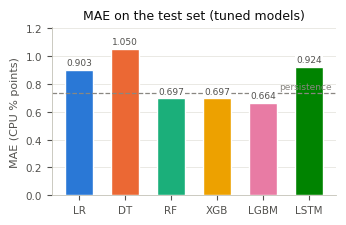

Saved figure: fig_rmse.png / .pdf


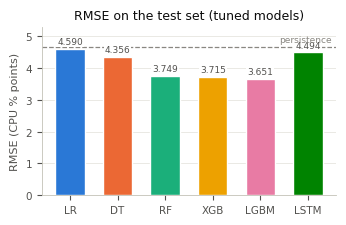

Saved figure: fig_r2.png / .pdf


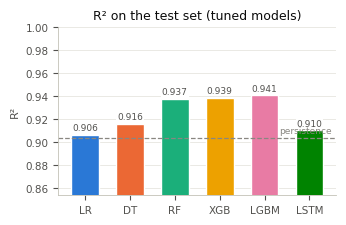

In [4]:
for metric, label, fname in (('MAE', 'MAE (CPU % points)', 'fig_mae'), ('RMSE', 'RMSE (CPU % points)', 'fig_rmse'),
                             ('R2', 'R²', 'fig_r2')):
    fig, ax = plt.subplots(figsize=(ONE_COL, 2.3))
    bar(ax, decision[metric].to_dict(), fmt='{:.3f}')
    ax.axhline(persistence[metric], color=MUTED, ls='--', lw=0.9)
    ax.annotate('persistence', (len(ORDER) - 0.5, persistence[metric]), xytext=(0, 2),
                textcoords='offset points', ha='right', va='bottom', fontsize=6.5, color=MUTED)
    if metric == 'R2':
        lo = min(decision[metric].min(), persistence[metric])
        ax.set_ylim(max(0, lo - 0.05), 1.0)
    ax.set_ylabel(label)
    ax.set_title(f'{metric if metric != "R2" else "R²"} on the test set (tuned models)')
    save_fig(fig, fname)

Saved figure: fig_prediction_metrics_combined.png / .pdf


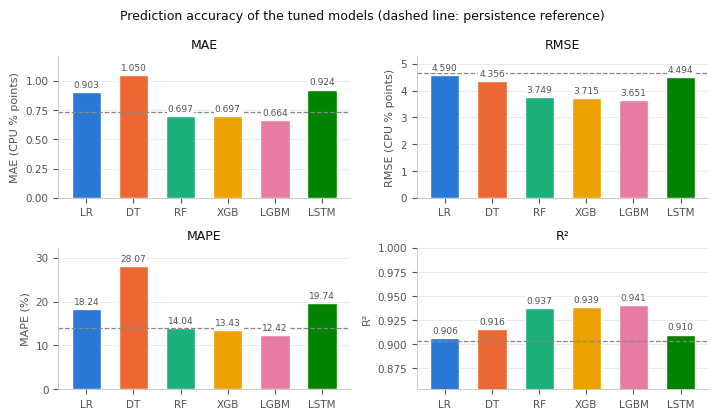

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(TWO_COL, 4.2))
for ax, (metric, label) in zip(axes.flat, [('MAE', 'MAE (CPU % points)'), ('RMSE', 'RMSE (CPU % points)'),
                                           ('MAPE', 'MAPE (%)'), ('R2', 'R²')]):
    bar(ax, decision[metric].to_dict(), fmt='{:.2f}' if metric == 'MAPE' else '{:.3f}')
    ax.axhline(persistence[metric], color=MUTED, ls='--', lw=0.9)
    if metric == 'R2':
        ax.set_ylim(max(0, min(decision[metric].min(), persistence[metric]) - 0.05), 1.0)
    ax.set_ylabel(label)
    ax.set_title(label.split(' (')[0])
fig.suptitle('Prediction accuracy of the tuned models (dashed line: persistence reference)', fontsize=9)
save_fig(fig, 'fig_prediction_metrics_combined')

## 3. Computational cost: training and inference time

Saved figure: fig_training_time.png / .pdf


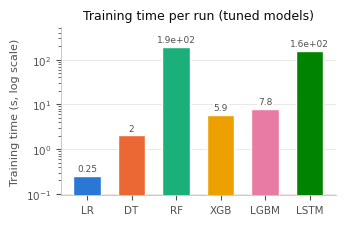

Saved figure: fig_inference_time.png / .pdf


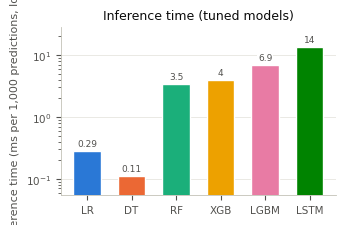

In [6]:
fig, ax = plt.subplots(figsize=(ONE_COL, 2.3))
bar(ax, decision['train_time_sec'].to_dict(), fmt='{:.2g}', log_scale=True)
ax.set_ylabel('Training time (s, log scale)')
ax.set_title('Training time per run (tuned models)')
save_fig(fig, 'fig_training_time')

fig, ax = plt.subplots(figsize=(ONE_COL, 2.3))
ms_per_1k = (1000 * tuned['inference_time_sec'] / (N_TEST / 1000)).to_dict()
bar(ax, ms_per_1k, fmt='{:.2g}', log_scale=True)
ax.set_ylabel('Inference time (ms per 1,000 predictions, log)')
ax.set_title('Inference time (tuned models)')
save_fig(fig, 'fig_inference_time')

## 4. Sustainability: energy and CO₂ per training run

Saved figure: fig_energy.png / .pdf


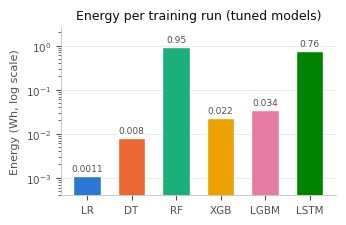

Saved figure: fig_co2.png / .pdf


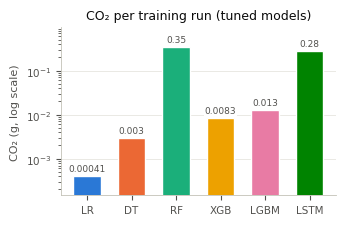

In [7]:
fig, ax = plt.subplots(figsize=(ONE_COL, 2.3))
bar(ax, (energy_t['energy_kwh'] * 1000).to_dict(), fmt='{:.2g}', log_scale=True)
ax.set_ylabel('Energy (Wh, log scale)')
ax.set_title('Energy per training run (tuned models)')
save_fig(fig, 'fig_energy')

fig, ax = plt.subplots(figsize=(ONE_COL, 2.3))
bar(ax, (energy_t['co2_emissions_kg'] * 1000).to_dict(), fmt='{:.2g}', log_scale=True)
ax.set_ylabel('CO₂ (g, log scale)')
ax.set_title('CO₂ per training run (tuned models)')
save_fig(fig, 'fig_co2')

## 5. Trade-offs: accuracy vs energy, accuracy vs time

Each point is one model, named directly. **Bottom-left is best**: low error and low cost. A model is "dominated" if another model is both more accurate and cheaper. The grey line joins the non-dominated models (the Pareto front), the ones a rational choice would come from.

Saved figure: fig_tradeoff_accuracy_vs_energy.png / .pdf


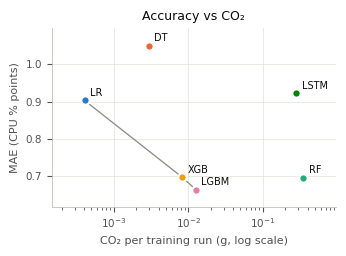

Saved figure: fig_tradeoff_accuracy_vs_time.png / .pdf


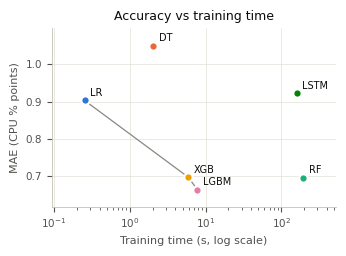

Pareto-optimal (MAE vs CO2): ['Linear Regression', 'XGBoost', 'LightGBM'] | (MAE vs time): ['Linear Regression', 'XGBoost', 'LightGBM']


In [8]:
def tradeoff(xcol, xlabel, title, fname, xscale=1.0):
    fig, ax = plt.subplots(figsize=(ONE_COL, 2.6))
    x = decision[xcol] * xscale
    y = decision['MAE']
    # Pareto front: sort by cost, keep points that improve on the best error so far
    front, best = [], np.inf
    for m in x.sort_values().index:
        if y[m] < best:
            front.append(m); best = y[m]
    ax.plot(x[front], y[front], color=MUTED, lw=0.9, ls='-', zorder=1)
    for m in ORDER:
        ax.scatter(x[m], y[m], s=36, color=COLOR[m], edgecolor='white', linewidth=1.5, zorder=3)
        ax.annotate(SHORT[m], (x[m], y[m]), xytext=(4, 3), textcoords='offset points', fontsize=7, color=INK)
    ax.set_xscale('log')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('MAE (CPU % points)')
    ax.set_title(title)
    ax.margins(x=0.15, y=0.12)
    save_fig(fig, fname)
    return front

f1 = tradeoff('co2_emissions_kg', 'CO₂ per training run (g, log scale)', 'Accuracy vs CO₂', 'fig_tradeoff_accuracy_vs_energy', 1000)
f2 = tradeoff('train_time_sec', 'Training time (s, log scale)', 'Accuracy vs training time', 'fig_tradeoff_accuracy_vs_time')
log.info(f'Pareto-optimal (MAE vs CO2): {f1} | (MAE vs time): {f2}')

## 6. TOPSIS ranking and weight sensitivity

Saved figure: fig_topsis_ranking.png / .pdf


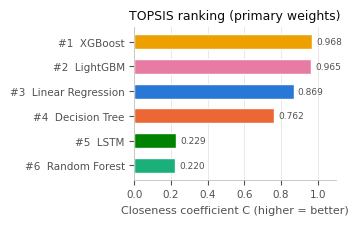

In [9]:
r = ranking.sort_values('Closeness C')
fig, ax = plt.subplots(figsize=(ONE_COL, 2.3))
ax.barh(np.arange(len(r)), r['Closeness C'], height=0.6, color=[COLOR[m] for m in r.Model], edgecolor='white')
ax.set_yticks(np.arange(len(r)), [f'#{k}  {m}' for k, m in zip(r.Rank, r.Model)])
for i, v in enumerate(r['Closeness C']):
    ax.annotate(f'{v:.3f}', (v, i), xytext=(3, 0), textcoords='offset points', va='center', fontsize=6.5, color=INK2)
ax.set_xlim(0, 1.1)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Closeness coefficient C (higher = better)')
ax.set_title('TOPSIS ranking (primary weights)')
save_fig(fig, 'fig_topsis_ranking')

Saved figure: fig_topsis_sensitivity.png / .pdf


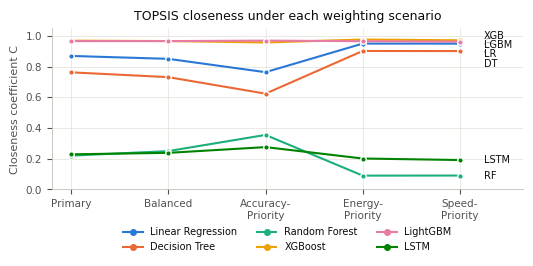

Saved figure: fig_topsis_weight_sweep.png / .pdf


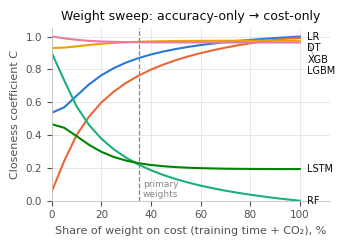

In [10]:
scen = [c[:-2] for c in sens.columns if c.endswith(' C')]
fig, ax = plt.subplots(figsize=(TWO_COL * 0.75, 2.8))
x = np.arange(len(scen))
for m in ORDER:
    vals = [sens.loc[m, f'{s} C'] for s in scen]
    ax.plot(x, vals, marker='o', ms=4, color=COLOR[m], lw=1.5, mec='white', mew=1)
end_labels(ax, x[-1] + 0.25, {m: sens.loc[m, f'{scen[-1]} C'] for m in ORDER}, min_gap=0.06)
ax.set_xticks(x, [s.replace('-', '-\n') for s in scen])
ax.set_xlim(-0.2, len(scen) - 0.35)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Closeness coefficient C')
ax.set_title('TOPSIS closeness under each weighting scenario')
ax.legend([plt.Line2D([], [], color=COLOR[m], marker='o', ms=4) for m in ORDER], ORDER,
          loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
save_fig(fig, 'fig_topsis_sensitivity')

fig, ax = plt.subplots(figsize=(ONE_COL, 2.5))
for m in ORDER:
    ax.plot(sweep['cost_weight_share'] * 100, sweep[f'C_{m}'], color=COLOR[m], lw=1.5)
end_labels(ax, 103, {m: sweep[f'C_{m}'].iloc[-1] for m in ORDER}, min_gap=0.07)
ax.axvline(35, color=MUTED, ls='--', lw=0.9)
ax.annotate('primary\nweights', (35, 0.02), xytext=(3, 0), textcoords='offset points', fontsize=6.5, color=MUTED)
ax.set_xlim(0, 112)
ax.set_ylim(0, 1.05)
ax.set_xlabel('Share of weight on cost (training time + CO₂), %')
ax.set_ylabel('Closeness coefficient C')
ax.set_title('Weight sweep: accuracy-only → cost-only')
save_fig(fig, 'fig_topsis_weight_sweep')

## 7. Radar chart: each model's profile on all six criteria

Each criterion is rescaled so that **1 = best model on that criterion and 0 = worst** (flipped for "lower is better" criteria). A big, even shape is a well-balanced model. The table version of this chart is the decision matrix (Table 1).

Saved figure: fig_radar.png / .pdf


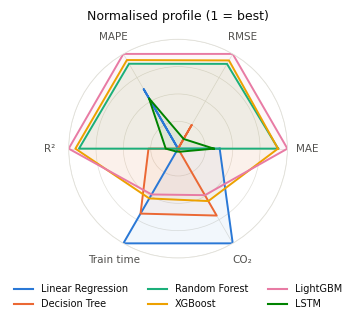

In [11]:
crit = ['MAE', 'RMSE', 'MAPE', 'R2', 'train_time_sec', 'co2_emissions_kg']
labels = ['MAE', 'RMSE', 'MAPE', 'R²', 'Train time', 'CO₂']
score = pd.DataFrame(index=ORDER)
for c in crit:
    v = decision[c]
    if c in ('train_time_sec', 'co2_emissions_kg'):
        v = np.log10(v)                      # costs span orders of magnitude
    s = (v - v.min()) / (v.max() - v.min())
    score[c] = s if C.TOPSIS_CRITERIA[c] else 1 - s
score.to_csv(C.TABLES_DIR / 'fig_radar_scores.csv')

angles = np.linspace(0, 2 * np.pi, len(crit), endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(figsize=(ONE_COL, 3.3), subplot_kw={'polar': True})
for m in ORDER:
    vals = score.loc[m].tolist(); vals += vals[:1]
    ax.plot(angles, vals, color=COLOR[m], lw=1.4)
    ax.fill(angles, vals, color=COLOR[m], alpha=0.06)
ax.set_xticks(angles[:-1], labels)
ax.set_yticks([0.25, 0.5, 0.75, 1.0], ['', '', '', ''])
ax.set_ylim(0, 1)
ax.spines['polar'].set_color(GRID)
ax.set_title('Normalised profile (1 = best)', pad=14)
ax.legend([plt.Line2D([], [], color=COLOR[m], lw=1.5) for m in ORDER], ORDER,
          loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
save_fig(fig, 'fig_radar')

## 8. Actual vs predicted CPU for one VM

Two days from the test period of one main-group VM. We pick the VM whose test-period CPU varies the most, so the chart actually shows the models reacting to changes. Plotted: actual CPU, the TOPSIS winner, the LSTM, and Linear Regression. Showing all six would turn the chart into spaghetti; the full numbers are in Table 1.

Saved figure: fig_actual_vs_predicted.png / .pdf


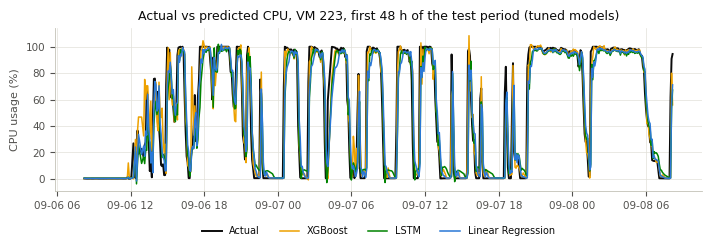

Actual-vs-predicted chart: VM 223, models ['XGBoost', 'LSTM', 'Linear Regression']


In [12]:
preds = pd.read_parquet(C.DATA_PROCESSED / 'test_predictions.parquet')
for m in ORDER:
    preds[f'tuned_{M.slug(m)}'] = np.load(C.MODELS_DIR / f'pred_test_tuned_{M.slug(m)}.npy')
vm = preds.groupby('vm_id')['actual'].std().idxmax()
p = preds[preds.vm_id == vm].sort_values('timestamp')
start = p['timestamp'].iloc[0]
p = p[p['timestamp'] < start + pd.Timedelta(days=2)]

winner = ranking.sort_values('Rank').Model.iloc[0]
show = [winner] + [m for m in ['LSTM', 'Linear Regression'] if m != winner]
fig, ax = plt.subplots(figsize=(TWO_COL, 2.6))
ax.plot(p['timestamp'], p['actual'], color=INK, lw=1.4, label='Actual')
for m in show:
    ax.plot(p['timestamp'], p[f'tuned_{M.slug(m)}'], color=COLOR[m], lw=1.1, label=m)
ax.set_ylabel('CPU usage (%)')
ax.set_title(f'Actual vs predicted CPU, VM {vm}, first 48 h of the test period (tuned models)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=len(show) + 1, frameon=False)
save_fig(fig, 'fig_actual_vs_predicted')
log.info(f'Actual-vs-predicted chart: VM {vm}, models {show}')

## 9. Stability across seeds and generalization to unseen VMs

Saved figure: fig_stability_errorbars.png / .pdf


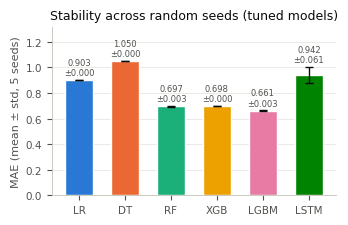

In [13]:
fig, ax = plt.subplots(figsize=(ONE_COL, 2.3))
x = np.arange(len(ORDER))
ax.bar(x, stab['MAE_mean'], width=0.62, color=[COLOR[m] for m in ORDER], edgecolor='white')
ax.errorbar(x, stab['MAE_mean'], yerr=stab['MAE_std'], fmt='none', ecolor=INK, elinewidth=1, capsize=3)
for xi, (mu, sd) in enumerate(zip(stab['MAE_mean'], stab['MAE_std'])):
    ax.annotate(f'{mu:.3f}\n±{sd:.3f}', (xi, mu + sd), xytext=(0, 2), textcoords='offset points',
                ha='center', va='bottom', fontsize=6, color=INK2)
ax.set_xticks(x, [SHORT[m] for m in ORDER])
ax.grid(axis='x', visible=False)
ax.margins(y=0.25)
ax.set_ylabel('MAE (mean ± std, 5 seeds)')
ax.set_title('Stability across random seeds (tuned models)')
save_fig(fig, 'fig_stability_errorbars')

Saved figure: fig_generalization.png / .pdf


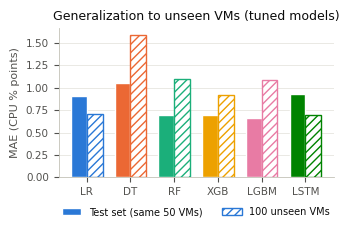

In [14]:
p4 = {m: (phase4[m]['MAE'] if m in phase4 else phase3.loc[m, 'MAE']) for m in ORDER}
fig, ax = plt.subplots(figsize=(ONE_COL, 2.4))
x = np.arange(len(ORDER)); w = 0.36
ax.bar(x - w / 2, [p4[m] for m in ORDER], width=w, color=[COLOR[m] for m in ORDER], edgecolor='white', label='Test set (same 50 VMs)')
ax.bar(x + w / 2, gen_t['MAE'], width=w, color='white', edgecolor=[COLOR[m] for m in ORDER], hatch='////',
       linewidth=1, label='100 unseen VMs')
ax.set_xticks(x, [SHORT[m] for m in ORDER])
ax.grid(axis='x', visible=False)
ax.set_ylabel('MAE (CPU % points)')
ax.set_title('Generalization to unseen VMs (tuned models)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
save_fig(fig, 'fig_generalization')

## 10. Final paper tables

Each table is saved as CSV (exact numbers) and PNG (formatted). Numbering here is only a working order; the LaTeX paper numbers its tables itself.

In [15]:
full = pd.DataFrame({
    'Model': ORDER,
    'MAE': decision['MAE'].values, 'RMSE': decision['RMSE'].values, 'MAPE (%)': decision['MAPE'].values,
    'R2': decision['R2'].values,
    'Train time (s)': decision['train_time_sec'].values,
    'Inference (ms/1k)': (1000 * tuned['inference_time_sec'] / (N_TEST / 1000)).values,
    'Energy (Wh)': (energy_t['energy_kwh'] * 1000).values,
    'CO2 (g)': (energy_t['co2_emissions_kg'] * 1000).values,
    'TOPSIS C': ranking.set_index('Model').loc[ORDER, 'Closeness C'].values,
    'TOPSIS rank': ranking.set_index('Model').loc[ORDER, 'Rank'].values,
})
U.save_table(full, 'table_full_results', 'Full results: tuned models', float_fmt='{:.4g}')

# The other tables come straight from earlier phases; re-export them under final names
copies = {
    'table_category_winners': ('phase7_category_winners.csv', 'Best model per criterion vs the TOPSIS recommendation'),
    'table_tuning_before_after': ('phase4_tuning_before_after.csv', 'Default vs tuned models (test set)'),
    'table_stability_summary': ('phase6_stability_summary.csv', 'Stability across 5 random seeds (mean ± std)'),
    'table_topsis_ranking': ('phase7_topsis_ranking.csv', 'TOPSIS ranking with the primary weights'),
    'table_topsis_sensitivity': ('phase8_sensitivity.csv', 'TOPSIS closeness and rank under each scenario'),
    'table_generalization': ('phase9_generalization_tuned.csv', 'Original test set vs 100 unseen VMs (tuned models)'),
    'table_generalization_default_models': ('phase9_generalization_default.csv', 'Original test set vs 100 unseen VMs (Phase 3 models)'),
    'table_energy': ('phase5_energy_tuned.csv', 'Energy and CO2 per training run (tuned models)'),
    'table_tuning_energy': ('phase5_tuning_energy_estimate.csv', 'Estimated energy of hyperparameter tuning'),
}
for new, (src, title) in copies.items():
    t = pd.read_csv(C.TABLES_DIR / src)
    U.save_table(t, new, title, float_fmt='{:.4g}')
    log.info(f'Saved table: {new} (from {src})')
full

Saved table: table_category_winners (from phase7_category_winners.csv)
Saved table: table_tuning_before_after (from phase4_tuning_before_after.csv)
Saved table: table_stability_summary (from phase6_stability_summary.csv)
Saved table: table_topsis_ranking (from phase7_topsis_ranking.csv)
Saved table: table_topsis_sensitivity (from phase8_sensitivity.csv)
Saved table: table_generalization (from phase9_generalization_tuned.csv)
Saved table: table_generalization_default_models (from phase9_generalization_default.csv)
Saved table: table_energy (from phase5_energy_tuned.csv)
Saved table: table_tuning_energy (from phase5_tuning_energy_estimate.csv)


,Model,MAE,RMSE,MAPE (%),R2,Train time (s),Inference (ms/1k),Energy (Wh),CO2 (g),TOPSIS C,TOPSIS rank
0,Linear Regression,0.903215,4.589898,18.240897,0.906246,0.253325,0.285940,0.001102,0.000407,0.868819,3
1,Decision Tree,1.050245,4.356144,28.067790,0.915553,2.041978,0.111458,0.007996,0.002954,0.762028,4
2,Random Forest,0.696579,3.749325,14.039768,0.937441,194.818086,3.461378,0.945826,0.349457,0.220108,6
3,XGBoost,0.697399,3.715139,13.426389,0.938577,5.920081,3.996194,0.022471,0.008303,0.968253,1
4,LightGBM,0.664048,3.650741,12.417047,0.940688,7.819682,6.936051,0.034244,0.012652,0.965244,2
5,LSTM,0.923798,4.493921,19.741333,0.910126,158.907845,13.633006,0.759287,0.280536,0.228620,5


## 11. Complete list of output files

In [16]:
manifest = []
for folder in (C.TABLES_DIR, C.CHARTS_DIR, C.LOGS_DIR):
    for f in sorted(folder.iterdir()):
        manifest.append({'Folder': folder.relative_to(C.PROJECT_ROOT).as_posix(), 'File': f.name,
                         'KB': round(f.stat().st_size / 1024, 1)})
manifest = pd.DataFrame(manifest)
manifest.to_csv(C.RESULTS / 'file_manifest.csv', index=False)
log.info(f'Figures produced in this phase: {len(saved_figs)} (each as PNG + PDF): {saved_figs}')
log.info(f'Files in results/: {len(manifest)} -> results/file_manifest.csv')
log.info('PHASE 10 COMPLETE')
manifest.groupby('Folder').size()

Figures produced in this phase: 17 (each as PNG + PDF): ['fig_mae', 'fig_rmse', 'fig_r2', 'fig_prediction_metrics_combined', 'fig_training_time', 'fig_inference_time', 'fig_energy', 'fig_co2', 'fig_tradeoff_accuracy_vs_energy', 'fig_tradeoff_accuracy_vs_time', 'fig_topsis_ranking', 'fig_topsis_sensitivity', 'fig_topsis_weight_sweep', 'fig_radar', 'fig_actual_vs_predicted', 'fig_stability_errorbars', 'fig_generalization']
Files in results/: 126 -> results/file_manifest.csv
PHASE 10 COMPLETE


,0
Folder,
results/charts,35
results/logs,12
results/tables,79


## Done: what to check

Open `results/charts/` in Drive and look at every figure: labels readable, nothing overlapping, and each model the same colour everywhere. If anything needs adjusting, tell the team. This notebook only redraws, so rerunning it is cheap.

Next: Phase 11, the publishability review (no notebook; Claude writes it up for the team).